In [ ]:
import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta

# 1. Generate modules.csv (Includes inconsistent module names)
modules_data = {
    'module': ['Auth', 'Payment', 'UI', 'Database', 'auth_module', 'PAYMENT', 'API_Gateway', 'Cache'],
    'component': ['Security', 'Finance', 'Frontend', 'Backend', 'Security', 'Finance', 'Backend', 'Backend'],
    'language': ['Python', 'Java', 'JavaScript', 'C++', 'Python', 'Java', 'Go', 'C++'],
    'size': [1200, 3500, 4200, 8500, 1200, 3500, 2100, 900]
}
pd.DataFrame(modules_data).to_csv('modules.csv', index=False)

# 2. Generate metrics.csv (Includes missing metric values and extreme complexity values)
metrics_data = {
    'module': ['Auth', 'Payment', 'UI', 'Database', 'API_Gateway', 'Cache', 'Auth', 'Payment'],
    'complexity': [12, 45, 18, 9999, 22, np.nan, 14, 8888], # 9999 and 8888 are extreme values
    'coupling': [4, 12, 5, 18, 8, 2, np.nan, 14],           # Missing value
    'churn': [50, 120, 300, 45, 80, 15, 60, np.nan],        # Missing value
    'test_coverage': [85.5, 60.2, 45.0, 92.1, 78.5, 95.0, 84.0, 58.5]
}
pd.DataFrame(metrics_data).to_csv('metrics.csv', index=False)

# 3. Generate defects.csv (Includes unmatched defect records)
defects_data = {
    'module': ['Auth', 'Payment', 'UI', 'Database', 'NonExistentModule', 'API_Gateway', 'Cache'],
    'defect_count': [5, 23, 41, 2, 99, 12, 1],
    'severity': ['High', 'Critical', 'Medium', 'Low', 'Critical', 'Medium', 'Low'],
    'release': ['v1.0', 'v1.0', 'v1.1', 'v1.0', 'v9.9', 'v1.1', 'v1.1']
}
pd.DataFrame(defects_data).to_csv('defects.csv', index=False)

# 4. Generate commits.csv
commits_data = {
    'module': ['Auth', 'Payment', 'UI', 'Database', 'API_Gateway', 'Cache'],
    'commit_count': [150, 420, 600, 85, 210, 40],
    'contributors': [3, 8, 12, 2, 5, 1],
    'changed_lines': [1200, 5400, 8900, 400, 2300, 150]
}
pd.DataFrame(commits_data).to_csv('commits.csv', index=False)

# 5. Generate releases.csv (Includes duplicate module-release rows)
releases_data = {
    'module': ['Auth', 'Payment', 'UI', 'Database', 'API_Gateway', 'Cache', 'Payment'], # Duplicate Payment
    'version': ['v1.0', 'v1.0', 'v1.1', 'v1.0', 'v1.1', 'v1.1', 'v1.0'],                # Duplicate v1.0
    'release_date': ['2026-01-15', '2026-01-15', '2026-03-20', '2026-01-15', '2026-03-20', '2026-03-20', '2026-01-15']
}
pd.DataFrame(releases_data).to_csv('releases.csv', index=False)

print("All 5 CSV files generated successfully!")

All 5 CSV files generated successfully!


In [ ]:
import pandas as pd
import numpy as np

# 1. Load the datasets
modules = pd.read_csv('modules.csv')
metrics = pd.read_csv('metrics.csv')
defects = pd.read_csv('defects.csv')
commits = pd.read_csv('commits.csv')
releases = pd.read_csv('releases.csv')

print("Data loaded successfully.")

# 2. Data Cleaning

# Condition A: Inconsistent module names
# Solution: Convert all module names to lowercase and remove redundant suffixes
for df in [modules, metrics, defects, commits, releases]:
    if 'module' in df.columns:
        df['module'] = df['module'].str.lower().str.replace('_module', '')

# Drop duplicates created in the modules dataframe after standardizing names
modules.drop_duplicates(subset=['module'], inplace=True)

# Condition B: Missing metric values
# Solution: Fill missing numerical values with the median of their respective columns
metrics.fillna(metrics.median(numeric_only=True), inplace=True)
# Also drop any duplicate module entries in metrics that might have been created
metrics = metrics.groupby('module', as_index=False).mean()

# Condition C: Extreme complexity values
# Solution: Cap extreme complexity values (e.g., > 1000) using the median complexity
median_complexity = metrics.loc[metrics['complexity'] < 1000, 'complexity'].median()
metrics.loc[metrics['complexity'] > 1000, 'complexity'] = median_complexity

# Condition D: Duplicate module-release rows
# Solution: Drop duplicate rows in the releases dataset
releases.drop_duplicates(inplace=True)

# Condition E: Unmatched defect records
# Solution: Filter the defects dataframe to only include modules that exist in modules.csv
valid_modules = modules['module'].unique()
defects = defects[defects['module'].isin(valid_modules)]

print("Data quality conditions resolved.")

# 3. Data Merging
# Combine all cleaned datasets into a single master dataframe for analysis
master_df = modules.merge(metrics, on='module', how='left')
master_df = master_df.merge(commits, on='module', how='left')
master_df = master_df.merge(defects, on='module', how='left')
master_df = master_df.merge(releases, on='module', how='left')

# Check the final merged data
print("\nFinal Merged Dataset Info:")
print(master_df.info())
display(master_df.head())

Data loaded successfully.
Data quality conditions resolved.

Final Merged Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   module         6 non-null      object 
 1   component      6 non-null      object 
 2   language       6 non-null      object 
 3   size           6 non-null      int64  
 4   complexity     6 non-null      float64
 5   coupling       6 non-null      float64
 6   churn          6 non-null      float64
 7   test_coverage  6 non-null      float64
 8   commit_count   6 non-null      int64  
 9   contributors   6 non-null      int64  
 10  changed_lines  6 non-null      int64  
 11  defect_count   6 non-null      int64  
 12  severity       6 non-null      object 
 13  release        6 non-null      object 
 14  version        6 non-null      object 
 15  release_date   6 non-null      object 
dtypes: float64(4),

,module,component,language,size,complexity,coupling,churn,test_coverage,commit_count,contributors,changed_lines,defect_count,severity,release,version,release_date
0,auth,Security,Python,1200,13.0,6.0,55.0,84.75,150,3,1200,5,High,v1.0,v1.0,2026-01-15
1,payment,Finance,Java,3500,20.0,13.0,90.0,59.35,420,8,5400,23,Critical,v1.0,v1.0,2026-01-15
2,ui,Frontend,JavaScript,4200,18.0,5.0,300.0,45.00,600,12,8900,41,Medium,v1.1,v1.1,2026-03-20
3,database,Backend,C++,8500,20.0,18.0,45.0,92.10,85,2,400,2,Low,v1.0,v1.0,2026-01-15
4,api_gateway,Backend,Go,2100,22.0,8.0,80.0,78.50,210,5,2300,12,Medium,v1.1,v1.1,2026-03-20


Descriptive Statistics:


,size,complexity,coupling,churn,test_coverage,commit_count,contributors,changed_lines,defect_count
count,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000
mean,3400.000000,19.166667,8.666667,97.500000,75.783333,250.833333,5.166667,3058.333333,14.000000
std,2808.558349,3.371449,5.853774,102.701022,19.702606,216.481331,4.167333,3439.828000,15.543487
min,900.000000,13.000000,2.000000,15.000000,45.000000,40.000000,1.000000,150.000000,1.000000
25%,1425.000000,18.500000,5.250000,47.500000,64.137500,101.250000,2.250000,600.000000,2.750000
50%,2800.000000,20.000000,7.000000,67.500000,81.625000,180.000000,4.000000,1750.000000,8.500000
75%,4025.000000,21.500000,11.750000,87.500000,90.262500,367.500000,7.250000,4625.000000,20.250000
max,8500.000000,22.000000,18.000000,300.000000,95.000000,600.000000,12.000000,8900.000000,41.000000


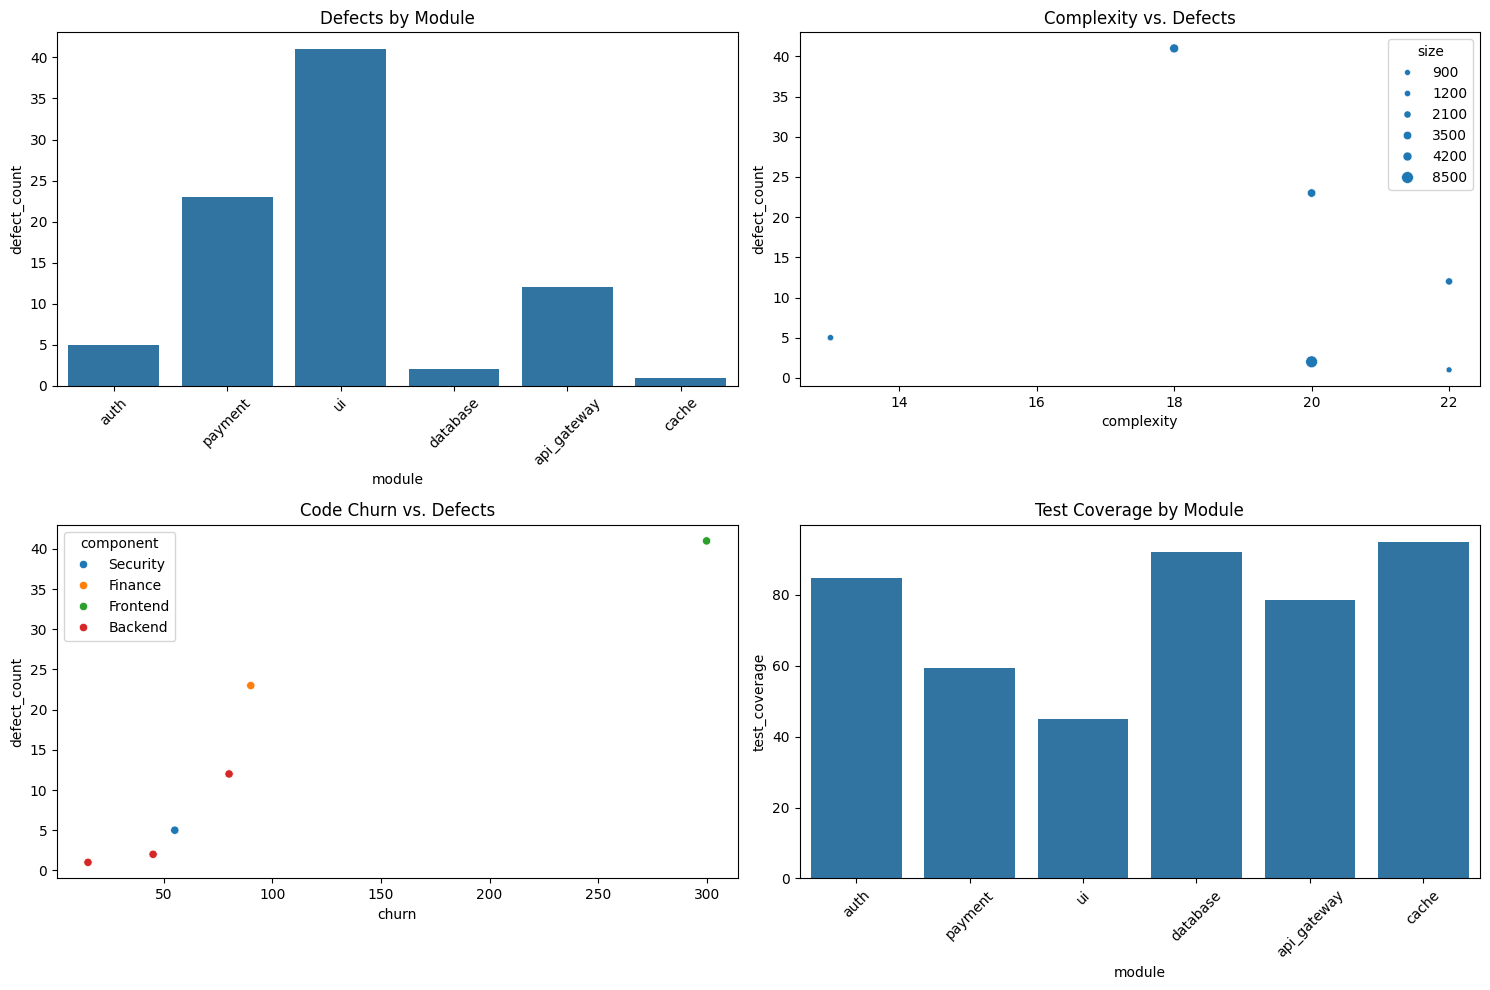


Engineered Features Added: severity_encoded, defect_density, risk_score


,module,severity_encoded,defect_density,risk_score
0,auth,3,4.166667,54.166667
1,payment,4,6.571429,131.428571
2,ui,2,9.761905,175.714286
3,database,1,0.235294,4.705882
4,api_gateway,2,5.714286,125.714286



Dataset successfully exported as 'cleaned_software_data.csv' for Excel analysis.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Descriptive Analysis
print("Descriptive Statistics:")
display(master_df.describe())

# 2. EDA Visualizations
plt.figure(figsize=(15, 10))

# Q: Which modules have more defects?
plt.subplot(2, 2, 1)
sns.barplot(x='module', y='defect_count', data=master_df)
plt.title('Defects by Module')
plt.xticks(rotation=45)

# Q: How does complexity relate to defects?
plt.subplot(2, 2, 2)
sns.scatterplot(x='complexity', y='defect_count', size='size', data=master_df)
plt.title('Complexity vs. Defects')

# Q: Does code churn relate to quality?
plt.subplot(2, 2, 3)
sns.scatterplot(x='churn', y='defect_count', hue='component', data=master_df)
plt.title('Code Churn vs. Defects')

# Q: How does test coverage differ?
plt.subplot(2, 2, 4)
sns.barplot(x='module', y='test_coverage', data=master_df)
plt.title('Test Coverage by Module')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# 3. Feature Engineering
# Encode categorical variable 'severity'
severity_map = {'Low': 1, 'Medium': 2, 'High': 3, 'Critical': 4}
master_df['severity_encoded'] = master_df['severity'].map(severity_map)

# Create new meaningful feature: defect_density (defects per 1000 lines of code)
master_df['defect_density'] = (master_df['defect_count'] / master_df['size']) * 1000

# Create risk score based on complexity and defect density
master_df['risk_score'] = master_df['complexity'] * master_df['defect_density']

print("\nEngineered Features Added: severity_encoded, defect_density, risk_score")
display(master_df[['module', 'severity_encoded', 'defect_density', 'risk_score']].head())

# 4. Export Cleaned Dataset for Excel (Round 3)
master_df.to_csv('cleaned_software_data.csv', index=False)
print("\nDataset successfully exported as 'cleaned_software_data.csv' for Excel analysis.")